# House price prediction model

Loading the dataset

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df=pd.read_csv("hpld.csv")

Display the first five records.

In [65]:
df.head()

,area_sqft,bedrooms,bathrooms,age_years,parking_spaces,price_lakhs
0,463,1,1,3,0,15.0
1,466,1,1,18,2,15.0
2,468,2,2,0,1,15.0
3,475,1,2,14,1,15.0
4,485,2,2,15,1,15.0


Find the number of rows and columns.

In [66]:
df.shape

(500, 6)

Identify the data types.

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_sqft       500 non-null    int64  
 1   bedrooms        500 non-null    int64  
 2   bathrooms       500 non-null    int64  
 3   age_years       500 non-null    int64  
 4   parking_spaces  500 non-null    int64  
 5   price_lakhs     500 non-null    float64
dtypes: float64(1), int64(5)
memory usage: 23.6 KB


Check whether any missing values exist.

In [68]:
df.isnull().sum().sum()

np.int64(0)

# Exploratory Data Analysis (EDA)

What is the average house price?
What is the minimum and maximum house price?
What is the average house area?
What is the average number of bedrooms?
What is the standard deviation of house prices?

In [69]:
print(df["price_lakhs"].mean())
print(df["price_lakhs"].min())
print(df["price_lakhs"].max())
print(df["area_sqft"].mean())  
print(df["bedrooms"].mean())
print(df["price_lakhs"].std())

28.83032
15.0
58.8
1722.906
3.292
10.552731940137624


# Visual analaysis

Create a scatter plot of all the features and the prices

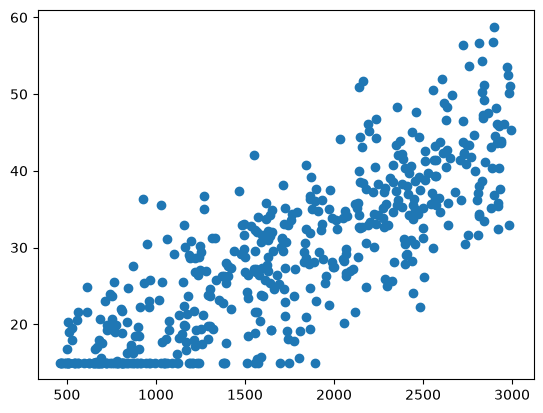

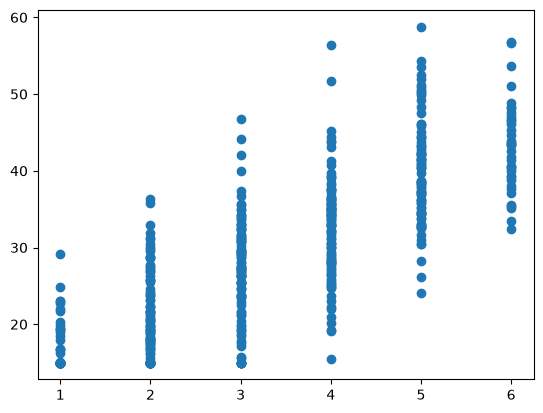

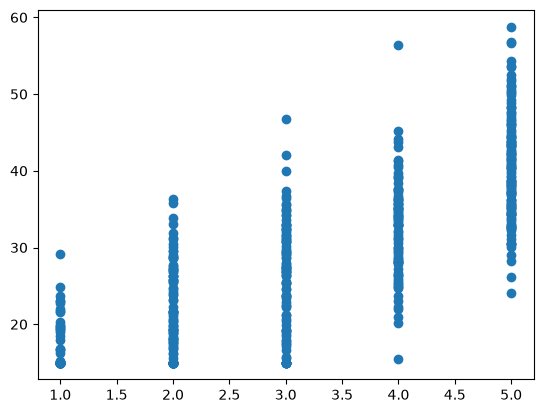

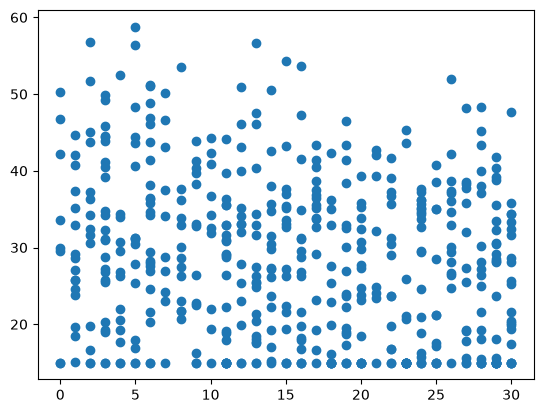

In [70]:
X=df["area_sqft"]
Y=df["price_lakhs"] 
plt.scatter(X,Y)
plt.show()
X=df["bedrooms"]
Y=df["price_lakhs"]
plt.scatter(X,Y)
plt.show()
x=df["bathrooms"]
y=df["price_lakhs"]
plt.scatter(x,y)
plt.show()
X=df["age_years"]
Y=df["price_lakhs"]     
plt.scatter(X,Y)    
plt.show()

# Distribution Analysis

House Price Prediction

(array([132.,  49.,  62.,  64.,  80.,  44.,  36.,  17.,  12.,   4.]),
 array([15.  , 19.38, 23.76, 28.14, 32.52, 36.9 , 41.28, 45.66, 50.04,
        54.42, 58.8 ]),
 <BarContainer object of 10 artists>)

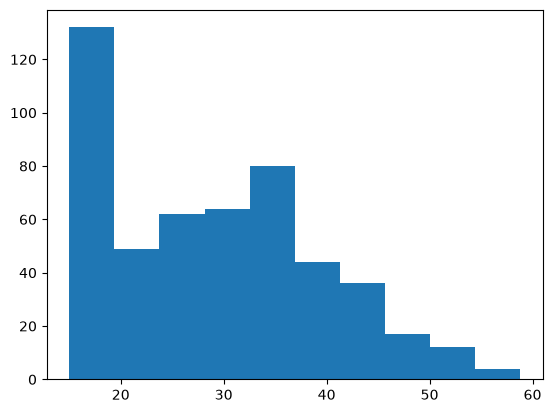

In [71]:
plt.hist(df["price_lakhs"])

Area Distribution

(array([132.,  49.,  62.,  64.,  80.,  44.,  36.,  17.,  12.,   4.]),
 array([15.  , 19.38, 23.76, 28.14, 32.52, 36.9 , 41.28, 45.66, 50.04,
        54.42, 58.8 ]),
 <BarContainer object of 10 artists>)

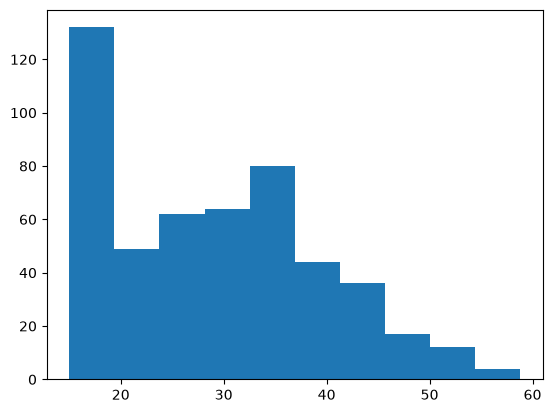

In [72]:
plt.hist(df["price_lakhs"])

# Parking VS Price

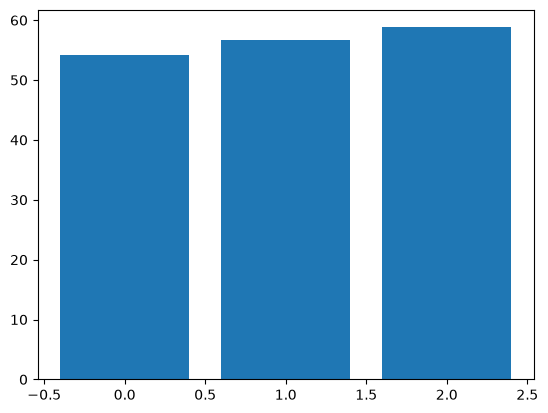

In [73]:
X=df["parking_spaces"]
Y=df["price_lakhs"]
plt.bar(X,Y)
plt.show()

# Correlation Analysis

<Axes: >

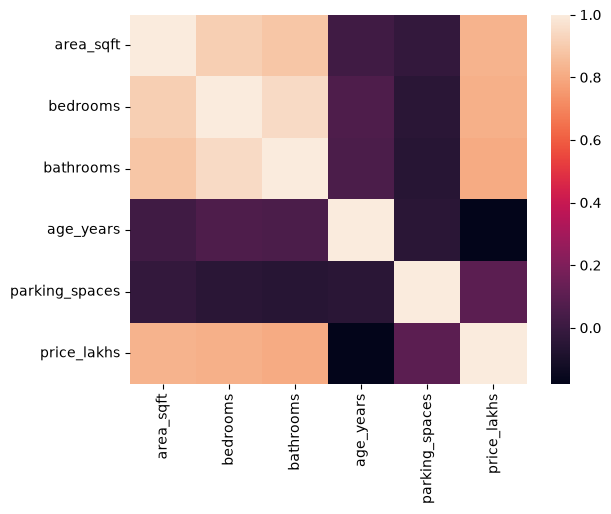

In [76]:
sns.heatmap(df.corr())

# Prepare features and target

In [4]:
X = df.drop('price_lakhs', axis=1)
y = df['price_lakhs']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 5)
(100, 5)
(400,)
(100,)


# Linear Regression Model

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
print(model.coef_)
print(model.intercept_)
y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})
comparison.head(10)

[ 0.00548511  2.06129329  1.48906262 -0.24272519  2.32587694]
9.171364534293708


,Actual Price,Predicted Price
361,25.04,31.490679
73,21.78,21.099088
374,42.10,37.096644
155,28.81,22.729508
104,22.24,24.274957
394,35.60,37.906896
377,35.27,39.791403
124,16.16,18.024402
68,15.00,15.827715
450,40.86,41.856446


# Evaluation Metrics

In [6]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.956473939229596
MSE: 24.95951372131312
RMSE: 4.995949731663952
R2 Score: 0.8117185993212575


# Actual VS Predicted Data

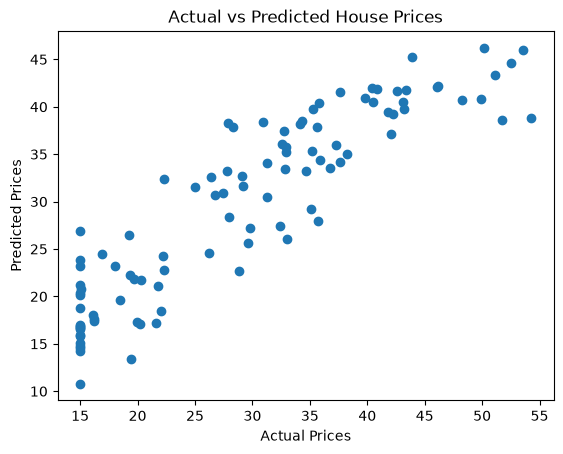

In [8]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()